# Задание 1. Классификация пингвинов (Palmer Penguins)

Датасет: Palmer Penguins. Классы: Adelie, Chinstrap, Gentoo. Количественные признаки: bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, roc_curve, auc

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
FEATURE_LABELS = {
    'bill_length_mm': 'длина клюва, мм',
    'bill_depth_mm': 'высота клюва, мм',
    'flipper_length_mm': 'длина ласта, мм',
    'body_mass_g': 'масса тела, г',
}

# цвет+форма на класс
STYLE = {
    'Adelie':    dict(color='#4C72B0', marker='o'),
    'Chinstrap': dict(color='#DD8452', marker='^'),
    'Gentoo':    dict(color='#55A868', marker='s'),
}
CLASSES_ALL = ['Adelie', 'Chinstrap', 'Gentoo']

plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## [1] Датасет

Palmer Penguins: 3 класса, 4 количественных признака (клюв x2, ласт, масса).

In [2]:
df = pd.read_csv('penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## [2] Статистика по датасету

Считаем размерность, число классов, пропуски, масштаб признаков. Затем формируем отфильтрованный датасет - убираем строки, где хоть один из 4 признаков не определён.

In [3]:
n_rows, n_cols = df.shape
print(f'Размер датасета: {n_rows} объектов x {n_cols} столбцов (из них 4 количественных признака)')

print('\nОбъектов по классам:')
print(df['species'].value_counts())

missing_pct = df[FEATURES].isna().mean() * 100
print('\n% пропусков по каждому из 4 признаков:')
print(missing_pct.round(2))

any_missing_pct = df[FEATURES].isna().any(axis=1).mean() * 100
print(f'\n% объектов с НЕ определённым хотя бы одним из 4 признаков: {any_missing_pct:.2f}%')

Размер датасета: 344 объектов x 8 столбцов (из них 4 количественных признака)

Объектов по классам:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

% пропусков по каждому из 4 признаков:
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
dtype: float64

% объектов с НЕ определённым хотя бы одним из 4 признаков: 0.58%


In [4]:
# масштаб признаков - разный (граммы vs мм) - стандартизируем
df[FEATURES].describe().loc[['mean', 'std', 'min', 'max']].round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0


In [5]:
# отфильтрованный датасет: убираем объекты с пропуском хотя бы в одном из 4 признаков
df_filtered = df.dropna(subset=FEATURES).reset_index(drop=True)
print(f'Было {len(df)} объектов, после фильтрации по 4 признакам: {len(df_filtered)}')
df_filtered['species'].value_counts()

Было 344 объектов, после фильтрации по 4 признакам: 342


species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

## [3] Визуализация по всем парам признаков

Матрица 4x4: на диагонали - гистограммы (20 бинов) по каждому признаку отдельно для каждого класса, вне диагонали - scatter по каждой паре признаков. Классы кодируются цветом и формой маркера одновременно.

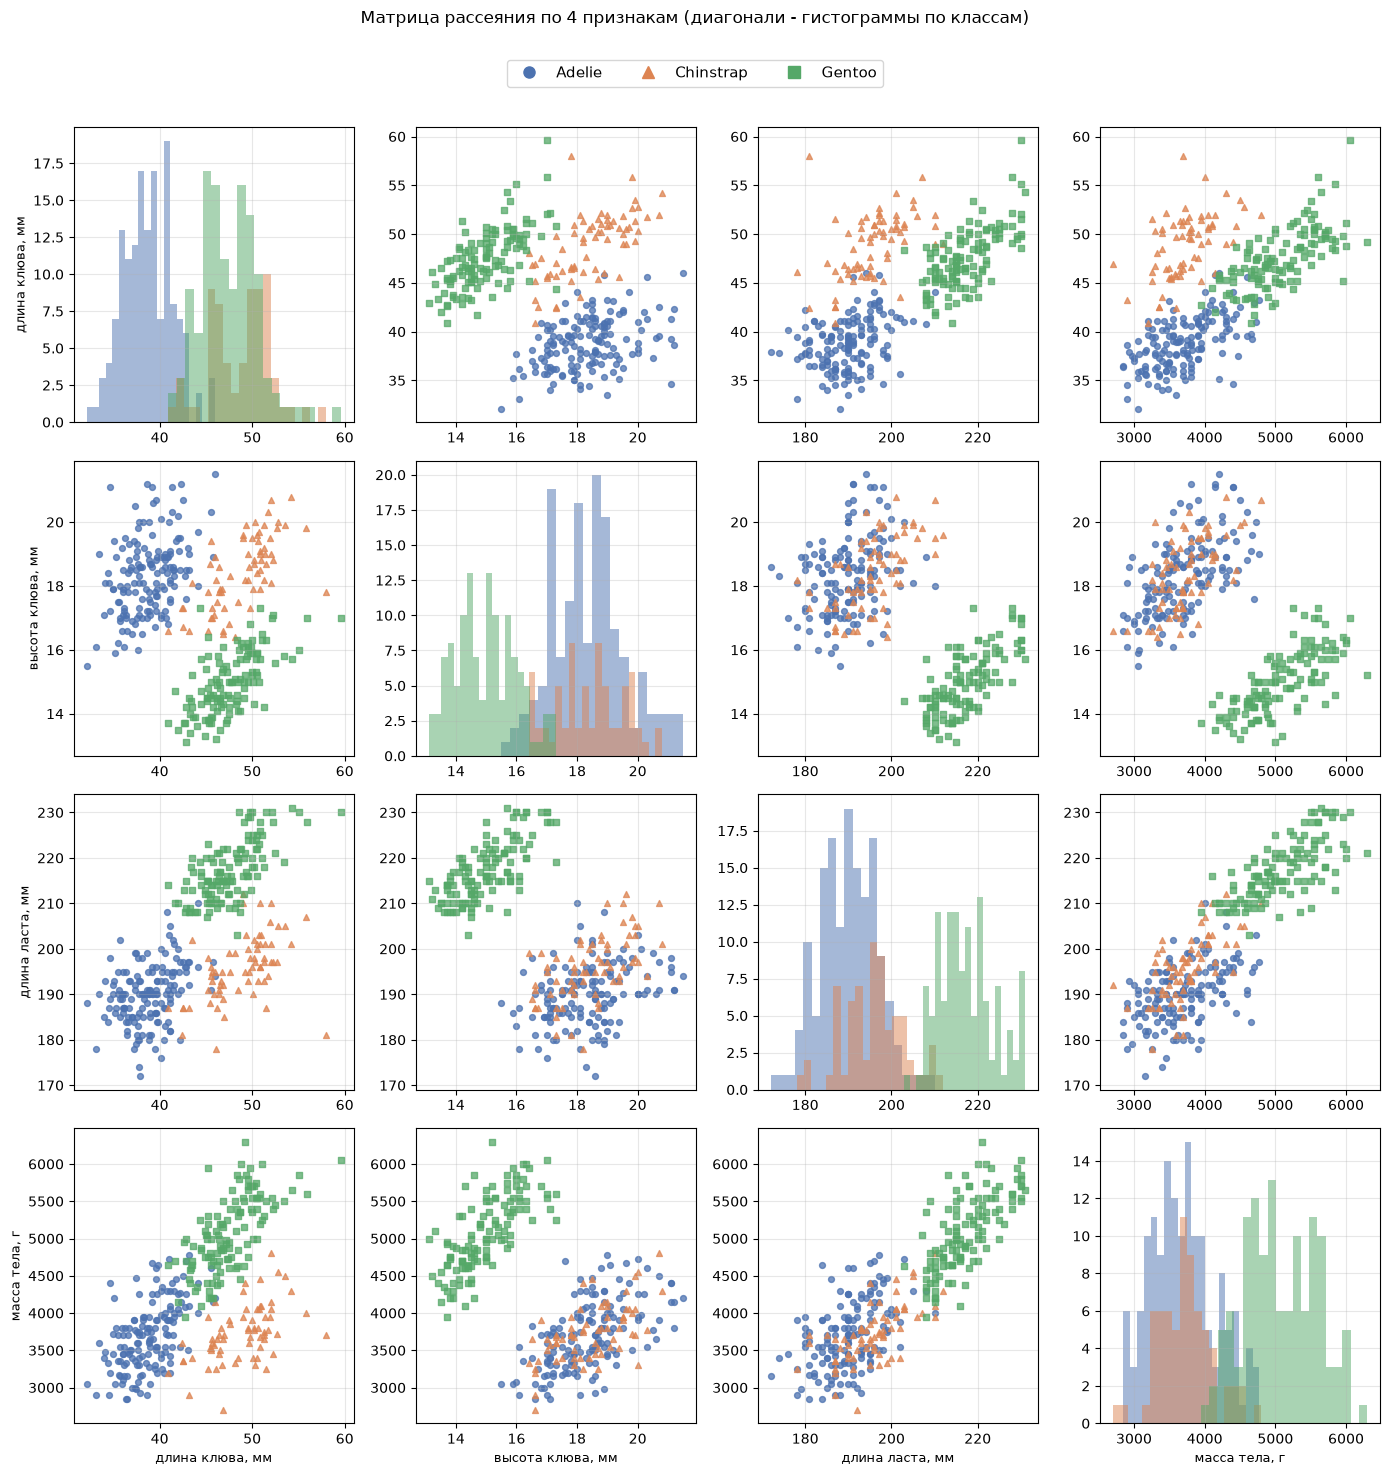

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))

for i, fi in enumerate(FEATURES):
    for j, fj in enumerate(FEATURES):
        ax = axes[i, j]
        if i == j:
            for cls in CLASSES_ALL:
                vals = df_filtered.loc[df_filtered['species'] == cls, fi]
                ax.hist(vals, bins=20, alpha=0.5, color=STYLE[cls]['color'], label=cls)
        else:
            for cls in CLASSES_ALL:
                sub = df_filtered[df_filtered['species'] == cls]
                ax.scatter(sub[fj], sub[fi], s=18, alpha=0.75,
                           color=STYLE[cls]['color'], marker=STYLE[cls]['marker'])
        if i == 3:
            ax.set_xlabel(FEATURE_LABELS[fj], fontsize=9)
        if j == 0:
            ax.set_ylabel(FEATURE_LABELS[fi], fontsize=9)

handles = [Line2D([0], [0], marker=STYLE[c]['marker'], color=STYLE[c]['color'],
                   linestyle='', markersize=8, label=c) for c in CLASSES_ALL]
fig.legend(handles=handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02), fontsize=11)
fig.suptitle('Матрица рассеяния по 4 признакам (диагонали - гистограммы по классам)', y=1.05)
plt.tight_layout()
plt.show()

## [4] Корреляция Пирсона

Сначала по всему отфильтрованному датасету (все классы вместе), затем отдельно внутри каждого класса.
Как: берём среднее по 2 признакам, для каждого объекта считаем отклонения, перемножаем, делим сумму по всем пингвинам на их количество. Получется ковариация (в какую сторону 2 измерения отклоняются от своих средних вместе). Делим это все на сумму квадратов стандартных отклонений (для каждго пингвина берём отклонения, возвдим в квадраты, складываем и делим на количество, берём корень)

In [7]:
print('Корреляция Пирсона по всему датасету (все классы смешаны):')
df_filtered[FEATURES].corr(method='pearson').round(2)

Корреляция Пирсона по всему датасету (все классы смешаны):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


In [8]:
for cls in CLASSES_ALL:
    print(f'\nКорреляция Пирсона внутри класса {cls}:')
    sub = df_filtered[df_filtered['species'] == cls]
    display(sub[FEATURES].corr(method='pearson').round(2))


Корреляция Пирсона внутри класса Adelie:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,0.39,0.33,0.55
bill_depth_mm,0.39,1.00,0.31,0.58
flipper_length_mm,0.33,0.31,1.00,0.47
body_mass_g,0.55,0.58,0.47,1.00



Корреляция Пирсона внутри класса Chinstrap:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,0.65,0.47,0.51
bill_depth_mm,0.65,1.00,0.58,0.60
flipper_length_mm,0.47,0.58,1.00,0.64
body_mass_g,0.51,0.60,0.64,1.00



Корреляция Пирсона внутри класса Gentoo:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,0.64,0.66,0.67
bill_depth_mm,0.64,1.00,0.71,0.72
flipper_length_mm,0.66,0.71,1.00,0.70
body_mass_g,0.67,0.72,0.70,1.00


## [5] LDA на паре классов (Adelie vs Chinstrap), все 4 признака

Берём пару классов Adelie/Chinstrap, обучаем LDA на всех 4 признаках (со стандартизацией - масштабы у признаков разные). Решающая функция рисуется проекцией на каждую пару осей: две оставшиеся координаты фиксируются на их среднем значении.

1. Берём центры облаков
2. считаем разность центров
3. для каждого пингвина считаем его отклоонение от среднего
4. Возводим отклонения в квадрат и усредняем. ЛДА объединяет данные о разбросе внутри обоих классов. По отклонениям пингвинов обоих видов получаем три числа. Квадраты отклонений дают дисперсии длины и высоты. Произведения двух отклонений дают ковариацию, которая учитывает, как длина и высота меняются вместе
5. Разность центров и три числа разброса подставляем в два уравнения:

Допустим разность центров равна (6, 2). Дисперсия длины клюва — 9, дисперсия высоты — 1, ковариация — 1. Подставляем эти числа в два уравнения:
9w_x + w_y = 6
w_x + w_y = 2

Получаем веса w_x=0.5 и w_y=1.5. Наклон прямой -w_x/w_y=-1/3: на 3 мм вправо линия опускается на 1 мм.

In [9]:
df_pair = df_filtered[df_filtered['species'].isin(['Adelie', 'Chinstrap'])].reset_index(drop=True)
X_pair = df_pair[FEATURES].values
y_pair = df_pair['species'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_pair, y_pair, test_size=0.3, stratify=y_pair, random_state=RANDOM_STATE)

print(f'train: {len(X_train)}, test: {len(X_test)}')
pd.Series(y_train).value_counts()

train: 153, test: 66


Adelie       105
Chinstrap     48
Name: count, dtype: int64

In [10]:
lda4 = Pipeline([('scaler', StandardScaler()), ('lda', LinearDiscriminantAnalysis())])
lda4.fit(X_train, y_train)
print(f'accuracy train: {lda4.score(X_train, y_train):.3f}, test: {lda4.score(X_test, y_test):.3f}')

accuracy train: 0.967, test: 1.000


In [11]:
def plot_projection(ax, pipe, feat_i, feat_j, X_tr, y_tr, X_te, y_te, classes=('Adelie', 'Chinstrap')):
    '''Решающая область pipe, спроецированная на оси feat_i/feat_j.
    Остальные признаки фиксируются на среднем значении по обучающей выборке.'''
    fi, fj = FEATURES.index(feat_i), FEATURES.index(feat_j)
    fixed = X_tr.mean(axis=0)

    pad_i = (X_tr[:, fi].max() - X_tr[:, fi].min()) * 0.1
    pad_j = (X_tr[:, fj].max() - X_tr[:, fj].min()) * 0.1
    xi = np.linspace(X_tr[:, fi].min() - pad_i, X_tr[:, fi].max() + pad_i, 200)
    xj = np.linspace(X_tr[:, fj].min() - pad_j, X_tr[:, fj].max() + pad_j, 200)
    gi, gj = np.meshgrid(xi, xj)

    grid = np.tile(fixed, (gi.size, 1))
    grid[:, fi] = gi.ravel()
    grid[:, fj] = gj.ravel()
    pred = pipe.predict(grid)
    Z = (pred == classes[1]).astype(int).reshape(gi.shape)

    ax.contourf(gi, gj, Z, levels=[-0.5, 0.5, 1.5], colors=[STYLE[classes[0]]['color'], STYLE[classes[1]]['color']], alpha=0.15)
    ax.contour(gi, gj, Z, levels=[0.5], colors='k', linewidths=1.5)

    for cls in classes:
        tr_m = y_tr == cls
        te_m = y_te == cls
        ax.scatter(X_tr[tr_m, fi], X_tr[tr_m, fj], color=STYLE[cls]['color'], marker=STYLE[cls]['marker'],
                   s=30, alpha=0.9, edgecolors='k', linewidths=0.3, label=f'{cls} (train)')
        ax.scatter(X_te[te_m, fi], X_te[te_m, fj], facecolors='none', edgecolors=STYLE[cls]['color'],
                   marker=STYLE[cls]['marker'], s=45, linewidths=1.3, label=f'{cls} (test)')
    ax.set_xlabel(FEATURE_LABELS[feat_i], fontsize=9)
    ax.set_ylabel(FEATURE_LABELS[feat_j], fontsize=9)

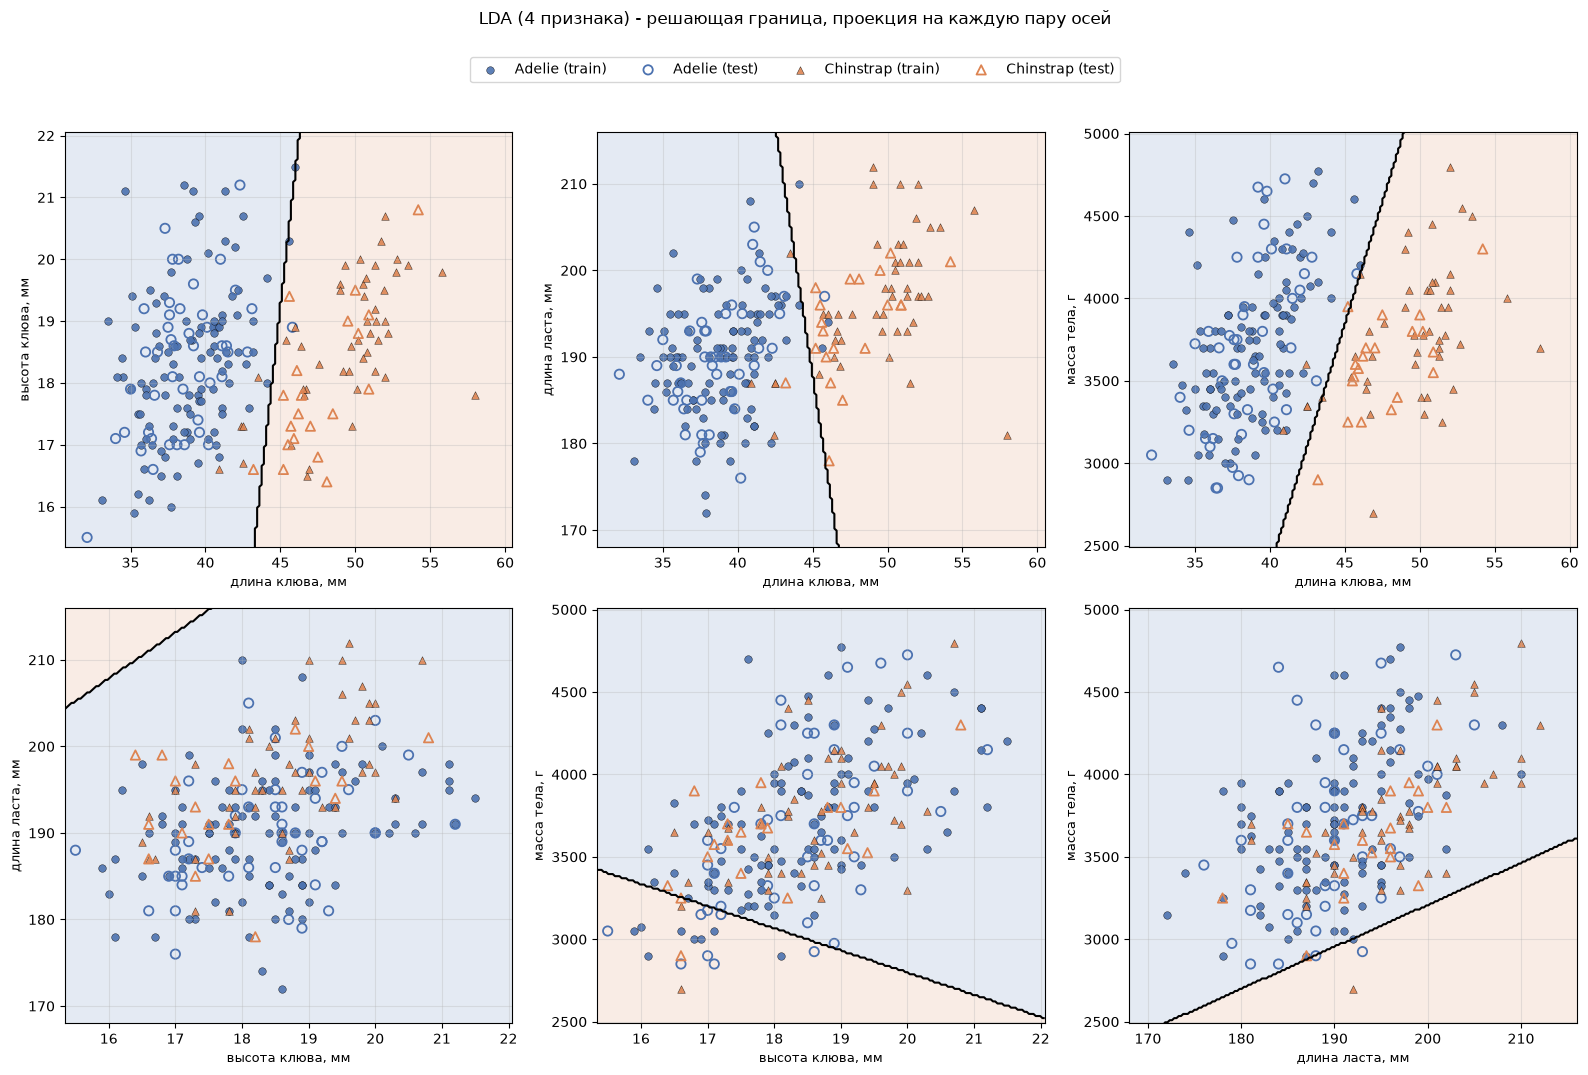

In [12]:
from itertools import combinations
pairs = list(combinations(FEATURES, 2))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (fi, fj) in zip(axes.ravel(), pairs):
    plot_projection(ax, lda4, fi, fj, X_train, y_train, X_test, y_test)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.03), fontsize=10)
fig.suptitle('LDA (4 признака) - решающая граница, проекция на каждую пару осей', y=1.07)
plt.tight_layout()
plt.show()

## [6] Одна пара признаков: LDA (проекция) + линейная регрессия

На паре bill_length_mm / bill_depth_mm - одновременно (а) решающая граница LDA из пункта [5] и (б) линейная регрессия одного признака от другого. Это разные задачи: регрессия идёт сквозь облако точек (минимизирует отклонения), LDA - между классами.

Лин рег - по длине предсказываем высоту
1. Находим среднюю длину и среднюю высоту
2. Считаем наклон. Ковариация длины и высоту делится на дисперсию длины (как два измерени отклоняются от своих средних вместе делим на насколько сильно длина разбросана вокруг среднего)

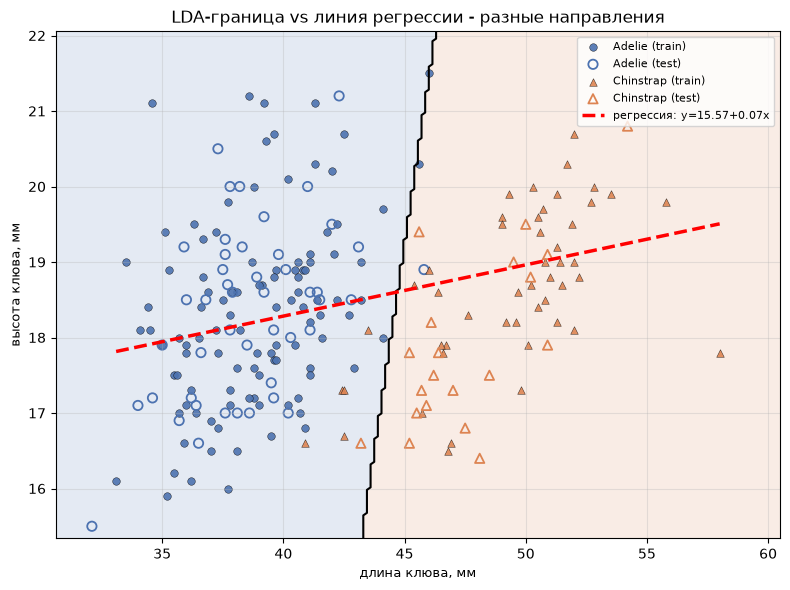

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_projection(ax, lda4, 'bill_length_mm', 'bill_depth_mm', X_train, y_train, X_test, y_test)

# линейная регрессия bill_depth ~ bill_length на этой же паре классов (train)
fi, fj = FEATURES.index('bill_length_mm'), FEATURES.index('bill_depth_mm')
reg = LinearRegression().fit(X_train[:, [fi]], X_train[:, fj])
x_line = np.linspace(X_train[:, fi].min(), X_train[:, fi].max(), 100).reshape(-1, 1)
y_line = reg.predict(x_line)
ax.plot(x_line, y_line, color='red', linewidth=2.5, linestyle='--',
        label=f'регрессия: y={reg.intercept_:.2f}+{reg.coef_[0]:.2f}x')

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, fontsize=8, loc='best')
ax.set_title('LDA-граница vs линия регрессии - разные направления')
plt.tight_layout()
plt.show()

## [7] LDA / SVM / LogReg / NaiveBayes на 2 признаках

Признаки: bill_length_mm, bill_depth_mm. Классы: Adelie, Chinstrap. Модели обучены напрямую на этих 2 признаках (без проекции).
1. SVM support vector machine - старается чтоб от неё до ближайших точек было как можно больше места.
2. Логистическая регрессия - насколько вероятно что пингвин чинстрап. Порог 0.5 - прямая
3. Наивный Байес выбирает вид, для которого размеры клюва выглядят более типичными.

In [14]:
X_train2 = X_train[:, [fi, fj]]
X_test2 = X_test[:, [fi, fj]]

models = {
    'LDA': Pipeline([('sc', StandardScaler()), ('clf', LinearDiscriminantAnalysis())]),
    'SVM': Pipeline([('sc', StandardScaler()), ('clf', SVC(kernel='linear', probability=True, random_state=RANDOM_STATE))]),
    'LogReg': Pipeline([('sc', StandardScaler()), ('clf', LogisticRegression(random_state=RANDOM_STATE))]),
    'NaiveBayes': Pipeline([('sc', StandardScaler()), ('clf', GaussianNB())]),
}
for m in models.values():
    m.fit(X_train2, y_train)

c:\Users\Peter\Study\machine-learning\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


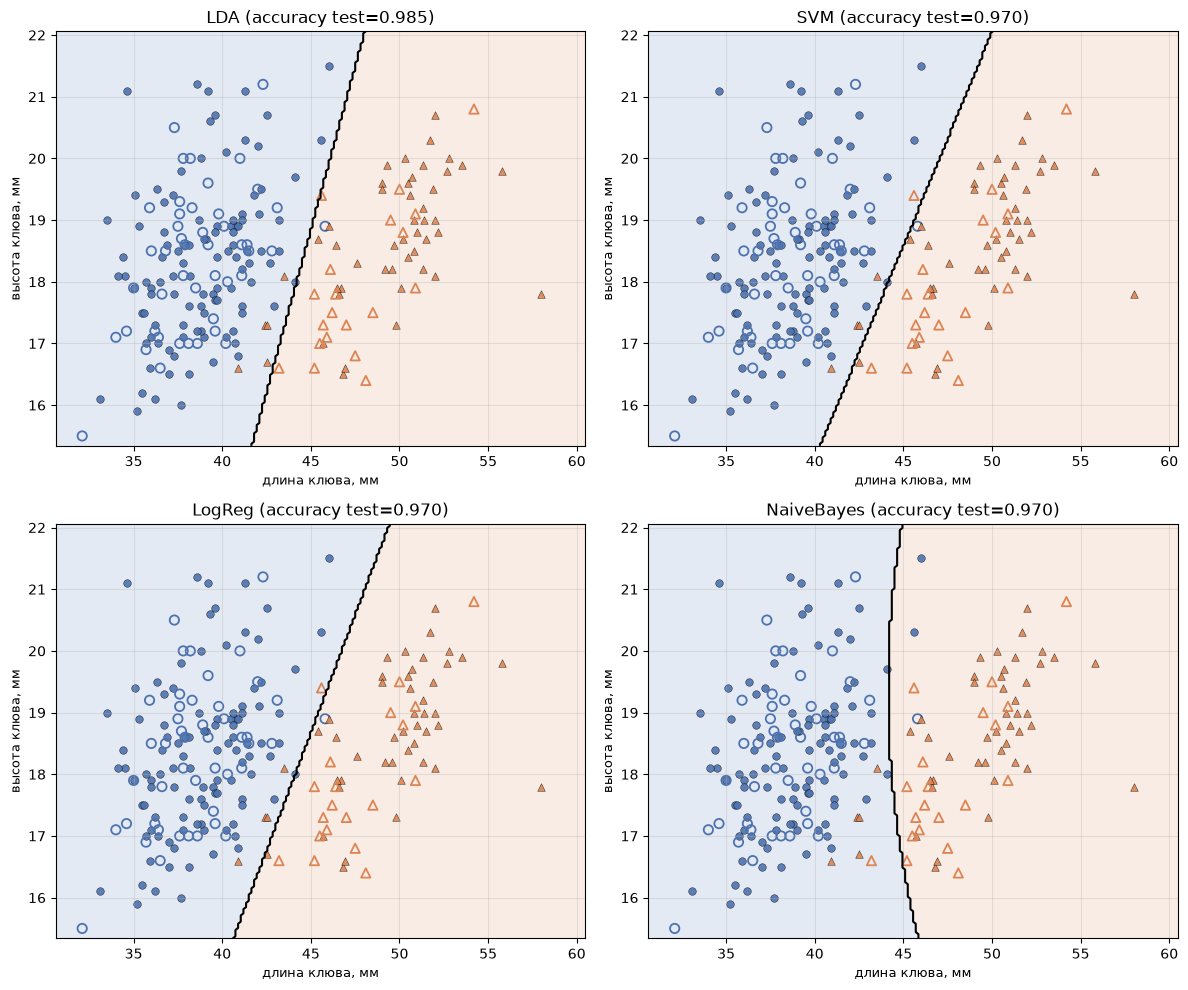

In [15]:
def plot_2d_region(ax, pipe, X_tr, y_tr, X_te, y_te, classes=('Adelie', 'Chinstrap')):
    pad_x = (X_tr[:, 0].max() - X_tr[:, 0].min()) * 0.1
    pad_y = (X_tr[:, 1].max() - X_tr[:, 1].min()) * 0.1
    xs = np.linspace(X_tr[:, 0].min() - pad_x, X_tr[:, 0].max() + pad_x, 200)
    ys = np.linspace(X_tr[:, 1].min() - pad_y, X_tr[:, 1].max() + pad_y, 200)
    gx, gy = np.meshgrid(xs, ys)
    pred = pipe.predict(np.c_[gx.ravel(), gy.ravel()])
    Z = (pred == classes[1]).astype(int).reshape(gx.shape)

    ax.contourf(gx, gy, Z, levels=[-0.5, 0.5, 1.5], colors=[STYLE[classes[0]]['color'], STYLE[classes[1]]['color']], alpha=0.15)
    ax.contour(gx, gy, Z, levels=[0.5], colors='k', linewidths=1.5)
    for cls in classes:
        tr_m, te_m = y_tr == cls, y_te == cls
        ax.scatter(X_tr[tr_m, 0], X_tr[tr_m, 1], color=STYLE[cls]['color'], marker=STYLE[cls]['marker'],
                   s=30, alpha=0.9, edgecolors='k', linewidths=0.3)
        ax.scatter(X_te[te_m, 0], X_te[te_m, 1], facecolors='none', edgecolors=STYLE[cls]['color'],
                   marker=STYLE[cls]['marker'], s=45, linewidths=1.3)
    ax.set_xlabel(FEATURE_LABELS['bill_length_mm'], fontsize=9)
    ax.set_ylabel(FEATURE_LABELS['bill_depth_mm'], fontsize=9)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    plot_2d_region(ax, m, X_train2, y_train, X_test2, y_test)
    acc = m.score(X_test2, y_test)
    ax.set_title(f'{name} (accuracy test={acc:.3f})')
plt.tight_layout()
plt.show()

## [8] Метрики для целевого класса Chinstrap

Confusion matrix и производные метрики считаются на test-выборке (модель их не видела при обучении). Chinstrap = positive класс.

Последний график — ROC-кривая. Слева направо растёт доля Adelie, которых модель ошибочно назвала Chinstrap. Снизу вверх растёт доля Chinstrap, которых она нашла. Каждая точка соответствует своему порогу: если снизить порог, модель будет чаще отвечать «Chinstrap». Хорошая кривая проходит близко к левому верхнему углу: много найденных Chinstrap и мало ложных тревог.

Sensitivity — какую долю настоящих Chinstrap нашли. Recall для того же класса означает ровно то же самое. Разница в употреблении: recall можно посчитать для каждого вида отдельно и затем усреднить по видам. В твоей таблице оба столбца относятся к Chinstrap, поэтому совпадают.

Specificity — какую долю настоящих Adelie правильно распознали. Precision — какая доля среди названных Chinstrap действительно Chinstrap. AUC — площадь под ROC-кривой. Чем ближе она к 1, тем чаще модель даёт настоящему Chinstrap более высокую оценку, чем Adelie.

In [16]:
TARGET = 'Chinstrap'
rows = []
roc_data = {}

for name, m in models.items():
    y_pred = m.predict(X_test2)
    y_true_bin = (y_test == TARGET)
    y_pred_bin = (y_pred == TARGET)

    tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin, labels=[False, True]).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = tp / (tp + fp) if (tp + fp) > 0 else float('nan')
    recall = sensitivity

    proba = m.predict_proba(X_test2)
    pos_idx = list(m.classes_).index(TARGET)
    scores = proba[:, pos_idx]
    fpr, tpr, _ = roc_curve(y_true_bin, scores)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = (fpr, tpr, roc_auc)

    rows.append(dict(model=name, TP=tp, FP=fp, TN=tn, FN=fn,
                      sensitivity=round(sensitivity, 3), specificity=round(specificity, 3),
                      precision=round(precision, 3), recall=round(recall, 3), AUC=round(roc_auc, 3)))

metrics_df = pd.DataFrame(rows).set_index('model')
metrics_df

,TP,FP,TN,FN,sensitivity,specificity,precision,recall,AUC
model,,,,,,,,,
LDA,20,1,45,0,1.00,0.978,0.952,1.00,0.998
SVM,19,1,45,1,0.95,0.978,0.950,0.95,0.999
LogReg,19,1,45,1,0.95,0.978,0.950,0.95,0.999
NaiveBayes,19,1,45,1,0.95,0.978,0.950,0.95,0.990


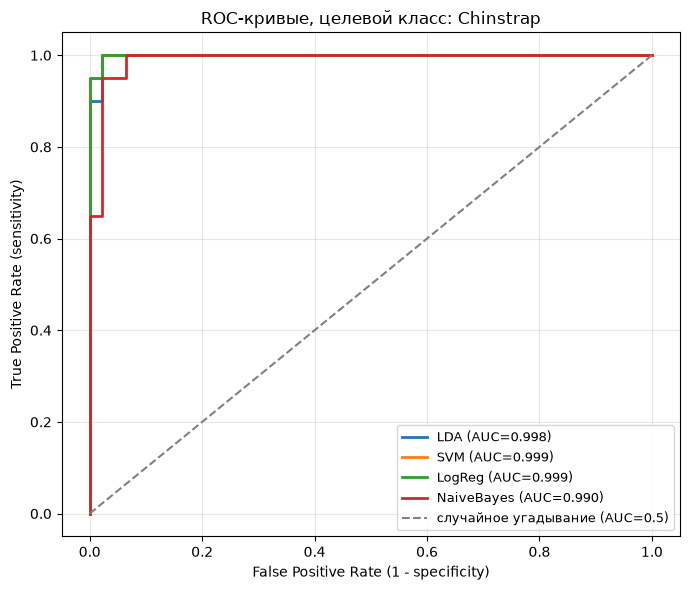

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, (fpr, tpr, roc_auc) in roc_data.items():
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={roc_auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='случайное угадывание (AUC=0.5)')
ax.set_xlabel('False Positive Rate (1 - specificity)')
ax.set_ylabel('True Positive Rate (sensitivity)')
ax.set_title(f'ROC-кривые, целевой класс: {TARGET}')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()